### Task II
Clustering Project
This project is clustering based project on the estimation of Obesity Levels Based On lifestyle and Physical Conditions. The dataset used in this work is downloaded from UCI: https://archive.ics.uci.edu/dataset/544/estimation+of+obesity+levels+based+on+eating+habits+and+physical+condition

The project will explore this dataset and apply clustering methods and models to make predictions

Gender	
<br>Age
<br>Height
<br>Weight
<br>family_history_with_overweight -  Has a family member suffered or suffers from overweight?
<br>FAVC - Do you eat high caloric food frequently?
<br>FCVC - Do you usually eat vegetables in your meals?
<br>NCP	- How many main meals do you have daily?
<br>CAEC - Do you eat any food between meals?
<br>SMOKE	- Do you smoke?
<br>CH2O - How much water do you drink daily?
<br>SCC - Do you monitor the calories you eat daily?
<br>FAF - How often do you have physical activity?
<br>TUE - How much time do you use technological devices such as cell phone, videogames, television, computer and others?
<br>CALC - How often do you drink alcohol?
<br>MTRANS - Which transportation do you usually use?
<br>NObeyesdad - TargetObesity  - level	

In [1]:
# importing libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
#Importing the data
df = pd.read_csv('ObesityDataSet_raw_and_data_sinthetic.csv')
df.head()

,Gender,Age,Height,Weight,family_history_with_overweight,FAVC,FCVC,NCP,CAEC,SMOKE,CH2O,SCC,FAF,TUE,CALC,MTRANS,NObeyesdad
0,Female,21.0,1.62,64.0,yes,no,2.0,3.0,Sometimes,no,2.0,no,0.0,1.0,no,Public_Transportation,Normal_Weight
1,Female,21.0,1.52,56.0,yes,no,3.0,3.0,Sometimes,yes,3.0,yes,3.0,0.0,Sometimes,Public_Transportation,Normal_Weight
2,Male,23.0,1.80,77.0,yes,no,2.0,3.0,Sometimes,no,2.0,no,2.0,1.0,Frequently,Public_Transportation,Normal_Weight
3,Male,27.0,1.80,87.0,no,no,3.0,3.0,Sometimes,no,2.0,no,2.0,0.0,Frequently,Walking,Overweight_Level_I
4,Male,22.0,1.78,89.8,no,no,2.0,1.0,Sometimes,no,2.0,no,0.0,0.0,Sometimes,Public_Transportation,Overweight_Level_II


In [3]:
df.shape

(2111, 17)

In [4]:
df.describe(include='all')

,Gender,Age,Height,Weight,family_history_with_overweight,FAVC,FCVC,NCP,CAEC,SMOKE,CH2O,SCC,FAF,TUE,CALC,MTRANS,NObeyesdad
count,2111,2111.000000,2111.000000,2111.000000,2111,2111,2111.000000,2111.000000,2111,2111,2111.000000,2111,2111.000000,2111.000000,2111,2111,2111
unique,2,NaN,NaN,NaN,2,2,NaN,NaN,4,2,NaN,2,NaN,NaN,4,5,7
top,Male,NaN,NaN,NaN,yes,yes,NaN,NaN,Sometimes,no,NaN,no,NaN,NaN,Sometimes,Public_Transportation,Obesity_Type_I
freq,1068,NaN,NaN,NaN,1726,1866,NaN,NaN,1765,2067,NaN,2015,NaN,NaN,1401,1580,351
mean,NaN,24.312600,1.701677,86.586058,NaN,NaN,2.419043,2.685628,NaN,NaN,2.008011,NaN,1.010298,0.657866,NaN,NaN,NaN
std,NaN,6.345968,0.093305,26.191172,NaN,NaN,0.533927,0.778039,NaN,NaN,0.612953,NaN,0.850592,0.608927,NaN,NaN,NaN
min,NaN,14.000000,1.450000,39.000000,NaN,NaN,1.000000,1.000000,NaN,NaN,1.000000,NaN,0.000000,0.000000,NaN,NaN,NaN
25%,NaN,19.947192,1.630000,65.473343,NaN,NaN,2.000000,2.658738,NaN,NaN,1.584812,NaN,0.124505,0.000000,NaN,NaN,NaN
50%,NaN,22.777890,1.700499,83.000000,NaN,NaN,2.385502,3.000000,NaN,NaN,2.000000,NaN,1.000000,0.625350,NaN,NaN,NaN
75%,NaN,26.000000,1.768464,107.430682,NaN,NaN,3.000000,3.000000,NaN,NaN,2.477420,NaN,1.666678,1.000000,NaN,NaN,NaN


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2111 entries, 0 to 2110
Data columns (total 17 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   Gender                          2111 non-null   object 
 1   Age                             2111 non-null   float64
 2   Height                          2111 non-null   float64
 3   Weight                          2111 non-null   float64
 4   family_history_with_overweight  2111 non-null   object 
 5   FAVC                            2111 non-null   object 
 6   FCVC                            2111 non-null   float64
 7   NCP                             2111 non-null   float64
 8   CAEC                            2111 non-null   object 
 9   SMOKE                           2111 non-null   object 
 10  CH2O                            2111 non-null   float64
 11  SCC                             2111 non-null   object 
 12  FAF                             21

In [6]:
df.duplicated().sum()

np.int64(24)

In [7]:
#dropping the duplicates
df.drop_duplicates(inplace=True)

#confirming the duplicates were dropped
df.duplicated().sum()

np.int64(0)

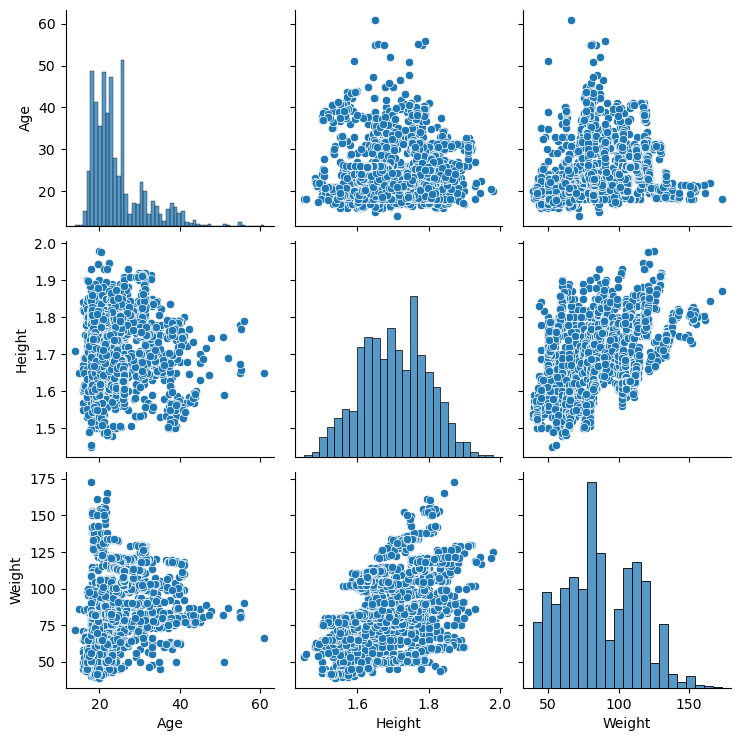

In [8]:
# Correlation between Age, Weight and Height
df_corr = df[['Age', 'Height', 'Weight']]
sns.pairplot(df_corr)

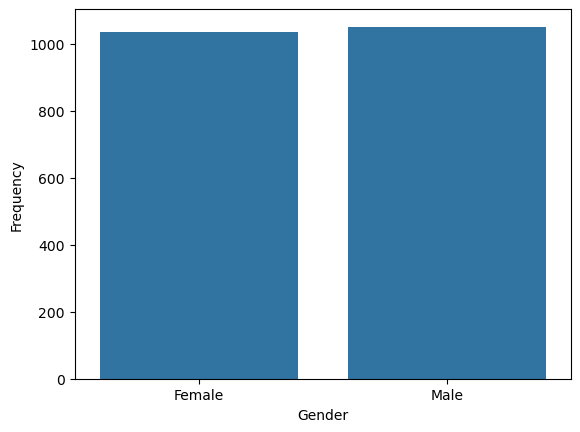

Gender
Male      1052
Female    1035
Name: count, dtype: int64


In [9]:
#Viewing the gender counts
sns.countplot(data=df, x='Gender')
plt.xlabel('Gender')
plt.ylabel('Frequency')
plt.show()

print(df['Gender'].value_counts())

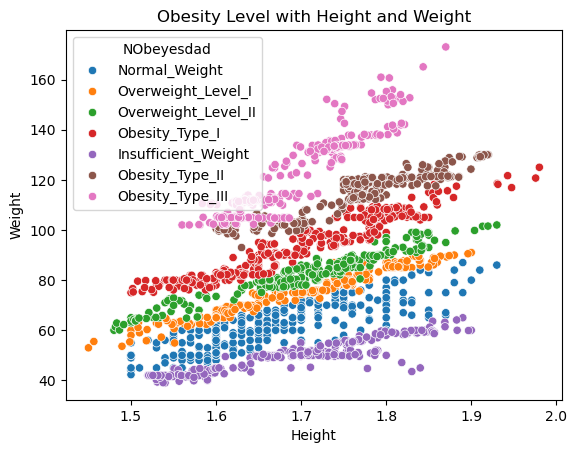

In [10]:
sns.scatterplot(x='Height', y='Weight', data=df, hue='NObeyesdad')
plt.title('Obesity Level with Height and Weight')
plt.show()

#### Feature Selection and Modelling 

The dataset in the project contain a class label 'NObeyesdad', For our Clustering task which is an unsupervised learning, a class label is not required. We drop our class label the 'NObeyesdad' 

In [11]:
dfnl = df.drop(labels='NObeyesdad', axis=1)
dfnl.head()

,Gender,Age,Height,Weight,family_history_with_overweight,FAVC,FCVC,NCP,CAEC,SMOKE,CH2O,SCC,FAF,TUE,CALC,MTRANS
0,Female,21.0,1.62,64.0,yes,no,2.0,3.0,Sometimes,no,2.0,no,0.0,1.0,no,Public_Transportation
1,Female,21.0,1.52,56.0,yes,no,3.0,3.0,Sometimes,yes,3.0,yes,3.0,0.0,Sometimes,Public_Transportation
2,Male,23.0,1.80,77.0,yes,no,2.0,3.0,Sometimes,no,2.0,no,2.0,1.0,Frequently,Public_Transportation
3,Male,27.0,1.80,87.0,no,no,3.0,3.0,Sometimes,no,2.0,no,2.0,0.0,Frequently,Walking
4,Male,22.0,1.78,89.8,no,no,2.0,1.0,Sometimes,no,2.0,no,0.0,0.0,Sometimes,Public_Transportation


##### Converting our categorical to numerical
First we manually map the categorical features with a boolean value to 0 and 1. Then Visualizing the unique values for our ordinal categories and using the ordinal encoder to convert to numerical values

In [12]:
# Manually mapping

dfnl['Gender'] = dfnl['Gender'].map({'Male': 1, 'Female': 0})
dfnl['family_history_with_overweight'] = dfnl['family_history_with_overweight'].map({'yes': 1, 'no': 0})
dfnl['FAVC'] = dfnl['FAVC'].map({'yes': 1, 'no': 0})
dfnl['SMOKE'] = dfnl['SMOKE'].map({'yes': 1, 'no': 0})
dfnl['SCC'] = dfnl['SCC'].map({'yes': 1, 'no': 0})


Visualizing the ordinal category unique values

In [13]:
df['CAEC'].unique()

array(['Sometimes', 'Frequently', 'Always', 'no'], dtype=object)

In [14]:
df['CALC'].unique()

array(['no', 'Sometimes', 'Frequently', 'Always'], dtype=object)

In [15]:
from sklearn.preprocessing import OrdinalEncoder

# Defining the order of each categorical feature
ordinal_cat = [
    ['no', 'Sometimes', 'Frequently', 'Always'],
    ['no', 'Sometimes', 'Frequently', 'Always']]

# Create the encoder
ord_enc = OrdinalEncoder(categories=ordinal_cat)
# Applying
dfnl[['CAEC', 'CALC']] = ord_enc.fit_transform(dfnl[['CAEC', 'CALC']])


In [16]:
# Converting to numerical using OneHotEncoder 
dfnl= pd.get_dummies(dfnl, columns=['MTRANS'], dtype=int, drop_first=True)

In [17]:
dfnl.head()

,Gender,Age,Height,Weight,family_history_with_overweight,FAVC,FCVC,NCP,CAEC,SMOKE,CH2O,SCC,FAF,TUE,CALC,MTRANS_Bike,MTRANS_Motorbike,MTRANS_Public_Transportation,MTRANS_Walking
0,0,21.0,1.62,64.0,1,0,2.0,3.0,1.0,0,2.0,0,0.0,1.0,0.0,0,0,1,0
1,0,21.0,1.52,56.0,1,0,3.0,3.0,1.0,1,3.0,1,3.0,0.0,1.0,0,0,1,0
2,1,23.0,1.80,77.0,1,0,2.0,3.0,1.0,0,2.0,0,2.0,1.0,2.0,0,0,1,0
3,1,27.0,1.80,87.0,0,0,3.0,3.0,1.0,0,2.0,0,2.0,0.0,2.0,0,0,0,1
4,1,22.0,1.78,89.8,0,0,2.0,1.0,1.0,0,2.0,0,0.0,0.0,1.0,0,0,1,0


In [18]:
from sklearn.preprocessing import StandardScaler

# Select non binary columns
cont_feat = dfnl.select_dtypes(include=['float64']).columns

# Scaling the continous data
sc = StandardScaler()
X = dfnl.copy()
X[cont_feat] = sc.fit_transform(dfnl[cont_feat])


In [19]:
X = X.iloc[:,1:18]

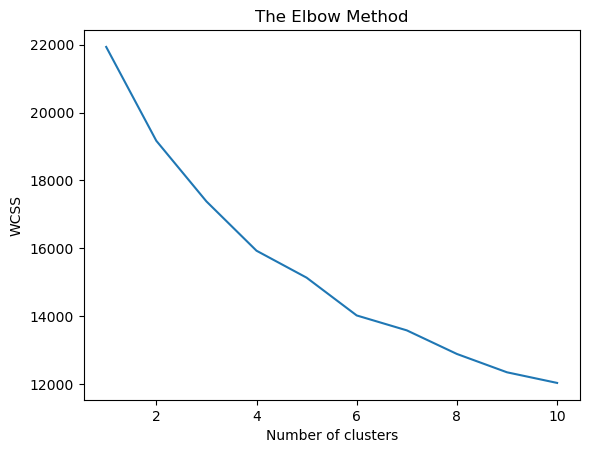

In [20]:
#Using the elbow method to find the optimal number of clusters
from sklearn.cluster import KMeans
wcss = []
for i in range(1, 11):
    kmeans = KMeans(n_clusters = i, init = 'k-means++', random_state=42)
    kmeans.fit(X)
    wcss.append(kmeans.inertia_)

plt.plot(range(1, 11), wcss)
plt.title('The Elbow Method')
plt.xlabel('Number of clusters')
plt.ylabel('WCSS')
plt.show()

#### K-Means Clustering

In [21]:
#Applying the Kmeans
kmeans = KMeans(n_clusters = 6, init = 'k-means++', random_state=42)
y_kmeans = kmeans.fit_predict(X)

In [22]:
#Reduction of the dimension for visualization
from sklearn.decomposition import PCA

pca = PCA(n_components=2)
x_pca = pca.fit_transform(X)

pca.explained_variance_ratio_

array([0.18627264, 0.15102302])

In [23]:
sum(pca.explained_variance_ratio_)

np.float64(0.337295664096935)

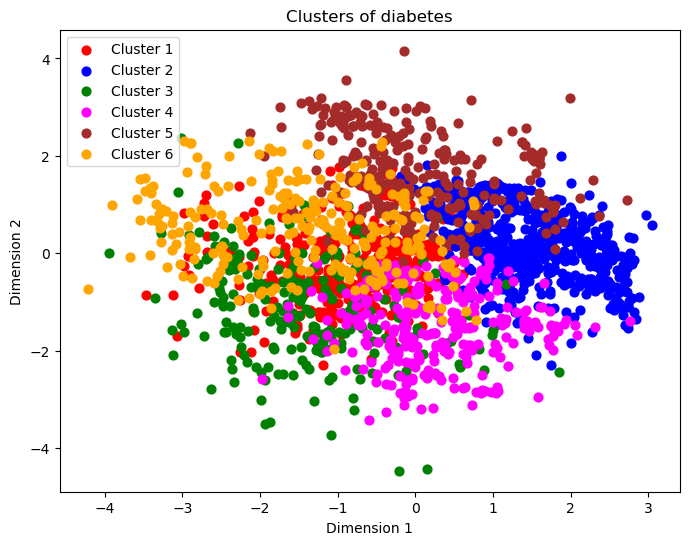

In [33]:
# Visualizing using the PCA
colours =['red', 'blue', 'green', 'magenta', 'brown', 'orange']

plt.figure(figsize=(8,6))
for i in range(6):
    plt.scatter(x_pca[y_kmeans == i, 0], x_pca[y_kmeans == i, 1],
                s=40, c = colours[i], label = 'Cluster '+str(i+1))
plt.title('Clusters of diabetes')
plt.xlabel('Dimension 1')
plt.ylabel('Dimension 2')
plt.legend()
plt.show()

In [32]:
#Applying the t-sne for clearer visual
from sklearn.manifold import TSNE
X_tsne = TSNE(n_components=2, perplexity=40).fit_transform(X)

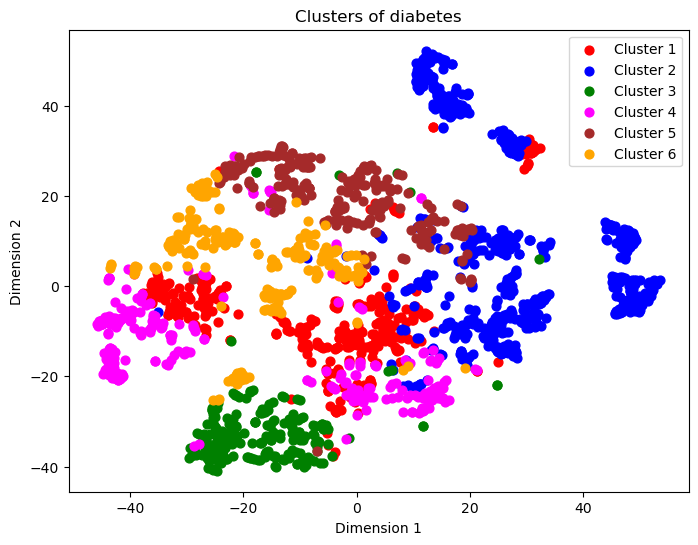

In [26]:
#Visualizing using the T-SNE
colours =['red', 'blue', 'green', 'magenta', 'brown', 'orange']

plt.figure(figsize=(8, 6))
for i in range(6):
    plt.scatter(X_tsne[y_kmeans == i, 0], X_tsne[y_kmeans == i, 1],
                s=40, c = colours[i], label = 'Cluster '+str(i+1))
plt.title('Clusters of diabetes')
plt.xlabel('Dimension 1')
plt.ylabel('Dimension 2')
plt.legend()
plt.show()

In [27]:
#Evaluating the silhouette
from sklearn.metrics import silhouette_score
score = silhouette_score(X, y_kmeans)

print("Silhouette Score:", round(score, 3))

Silhouette Score: 0.149


#### AgglomerativeClustering

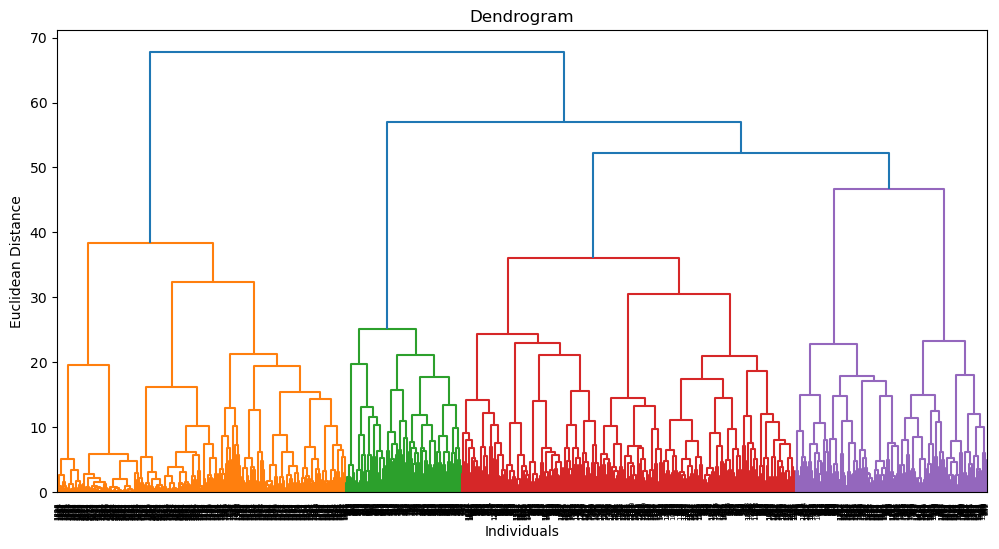

In [28]:
# Using the dendrogam to find the optimal number of cluster
import scipy.cluster.hierarchy as sch

plt.figure (figsize=(12,6))
dendrogram = sch.dendrogram(sch.linkage(X, method ='ward'))
plt.title('Dendrogram')
plt.xlabel('Individuals')
plt.ylabel('Euclidean Distance')
plt.show()


In [29]:
#Modelling with the Agglomerative Clustering
from sklearn.cluster import AgglomerativeClustering
hc = AgglomerativeClustering(n_clusters = 7, metric = 'euclidean', linkage = 'ward')
y_hc = hc.fit_predict(X)

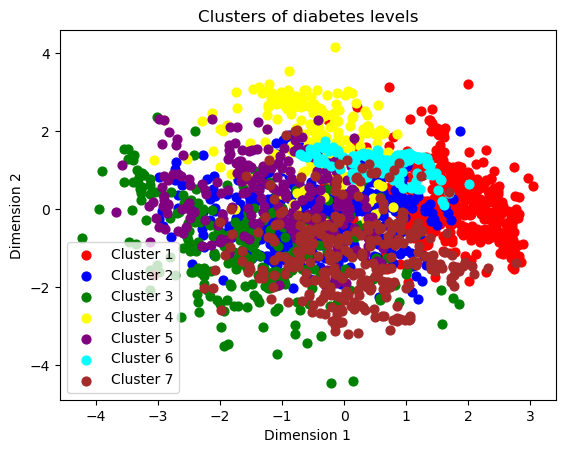

In [34]:
#Visualising using the PCA
colours =['red', 'blue', 'green', 'yellow', 'purple','cyan', 'brown']

# plt.figure(figsize=(10,8))
for i in range(7):
    plt.scatter(x_pca[y_hc == i, 0], x_pca[y_hc == i, 1],
                s=40, c = colours[i], label = 'Cluster '+str(i+1))
plt.title('Clusters of diabetes levels')
plt.xlabel('Dimension 1')
plt.ylabel('Dimension 2')
plt.legend()
plt.show()

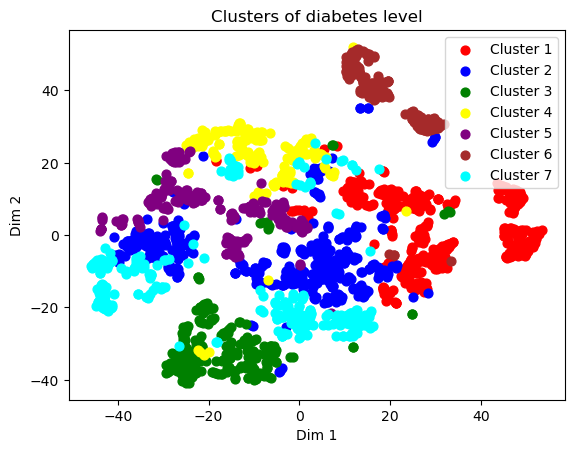

In [35]:
colours =['red', 'blue', 'green', 'yellow', 'purple', 'brown', 'cyan']

# plt.figure(figsize=(8,8))
for i in range(7):
    plt.scatter(X_tsne[y_hc == i, 0], X_tsne[y_hc == i, 1],
                s=40, c = colours[i], label = 'Cluster '+str(i+1))
plt.title('Clusters of diabetes level')
plt.xlabel('Dim 1')
plt.ylabel('Dim 2')
plt.legend()
plt.show()

In [36]:
score = silhouette_score(X, y_hc)

print("Silhouette Score:", round(score, 3))


Silhouette Score: 0.096
